<a href="https://colab.research.google.com/github/saleem7369/Consumer-Centric-ITS-Sleep-Behavior-in-Autonomous-Driving/blob/main/Consumer_centric_Sleep_order.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# prompt: mount file

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# prompt: display data here

import pandas as pd

# Assuming your data is in a CSV file named 'your_data.csv' in your Google Drive
# Replace 'your_data.csv' with the actual path to your file
file_path = '/content/drive/MyDrive/Colab Notebooks/RRS/RRS-028/Sleep_health_and_lifestyle_dataset.xlsx'

# Read the Excel file into a pandas DataFrame
df = pd.read_excel(file_path)  # This line is added to load the data

df.head()


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


In [ ]:
df.shape

(374, 13)

In [ ]:
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


**Preprocessing**

In [ ]:
# Let's drop unneeded columns for futher data processing.

df.drop('Person ID', axis=1, inplace=True)

In [ ]:
df.isna().sum()

,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0
Heart Rate,0


In [ ]:
df.fillna('None', inplace=True)

In [ ]:
# Reforming a column 'Blood Pressure' into two independent columns

df["High Pressure"] = 0
df["Low Pressure"] = 0

for i, val in enumerate(df["Blood Pressure"]):
    j = 0
    while val[j] != "/":
        j += 1
        continue

    df.loc[i, "High Pressure"] = int(val[:j])
    df.loc[i, "Low Pressure"] = int(val[(j+1):])

df = df.drop("Blood Pressure", axis=1)

In [ ]:
df.describe()

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,High Pressure,Low Pressure
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920,128.553476,84.649733
std,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679,7.748118,6.161611
min,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000,115.000000,75.000000
25%,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000,125.000000,80.000000
50%,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000,130.000000,85.000000
75%,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000,135.000000,90.000000
max,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000,142.000000,95.000000


In [ ]:
df['BMI Category'].unique()

array(['Overweight', 'Normal', 'Obese', 'Normal Weight'], dtype=object)

In [ ]:
# A column 'BMI Category' has values that are similar in meanings: 'Normal Weight' and 'Normal'
# Let's remane one of them.

df.loc[:, 'BMI Category'] = df['BMI Category'].replace({'Normal Weight': 'Normal'})

In [ ]:
# Looking closer into unique velues of the each column.

for i in df.columns:
    print(df[i].value_counts())
    print('')

Gender
Male      189
Female    185
Name: count, dtype: int64

Age
43    34
44    30
37    20
38    20
50    20
31    18
32    17
53    17
59    16
39    15
45    14
33    13
29    13
30    13
36    12
35    12
41    12
49    11
42     9
57     9
52     9
51     8
54     7
58     6
28     5
40     4
48     3
55     2
34     2
56     2
27     1
Name: count, dtype: int64

Occupation
Nurse                   73
Doctor                  71
Engineer                63
Lawyer                  47
Teacher                 40
Accountant              37
Salesperson             32
Scientist                4
Software Engineer        4
Sales Representative     2
Manager                  1
Name: count, dtype: int64

Sleep Duration
7.2    36
6.0    31
7.8    28
6.5    26
6.1    25
7.7    24
6.6    20
7.1    19
8.1    15
7.3    14
8.4    14
8.0    13
6.3    13
8.5    13
6.2    12
8.2    11
7.6    10
6.4     9
7.9     7
8.3     5
7.4     5
6.7     5
7.5     5
6.8     5
5.9     4
6.9     3
5.8     2
Name: co

In [ ]:
# processed data

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   374 non-null    object 
 1   Age                      374 non-null    int64  
 2   Occupation               374 non-null    object 
 3   Sleep Duration           374 non-null    float64
 4   Quality of Sleep         374 non-null    int64  
 5   Physical Activity Level  374 non-null    int64  
 6   Stress Level             374 non-null    int64  
 7   BMI Category             374 non-null    object 
 8   Heart Rate               374 non-null    int64  
 9   Daily Steps              374 non-null    int64  
 10  Sleep Disorder           374 non-null    object 
 11  High Pressure            374 non-null    int64  
 12  Low Pressure             374 non-null    int64  
dtypes: float64(1), int64(8), object(4)
memory usage: 38.1+ KB


In [ ]:
# deviding into columns with numerical and categorical values

cat_col = df.select_dtypes(include=["object"]).columns
num_col = df.select_dtypes(include=["int64", "float64"]).columns

histpot for numeric values

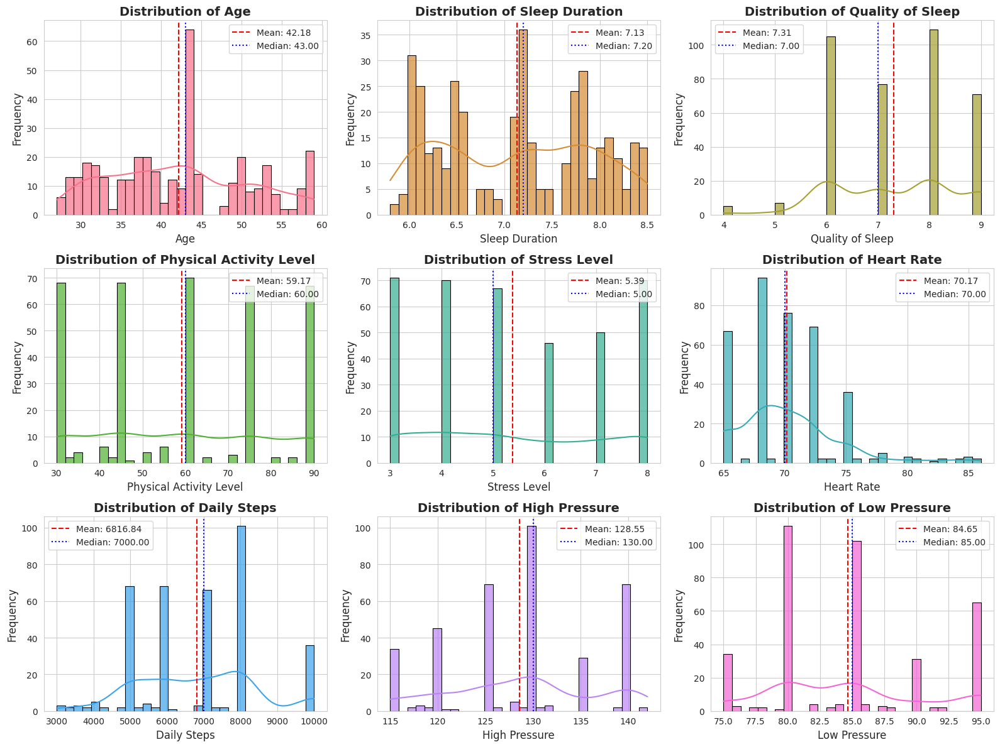

In [ ]:
# ===================== Improved Numerical Feature Distribution Plots =====================
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set a clean style
sns.set_style("whitegrid")

# Calculate subplot grid based on number of numeric columns
num_features = len(num_col)
num_cols = 3
num_rows = int(np.ceil(num_features / num_cols))

plt.figure(figsize=(16, num_rows * 4))  # Dynamic figure height

# Custom color palette
colors = sns.color_palette("husl", num_features)

for i, col in enumerate(num_col):
    plt.subplot(num_rows, num_cols, i + 1)

    # Histogram with KDE
    sns.histplot(df[col], kde=True, color=colors[i], bins=30, edgecolor="black", alpha=0.7)

    # Add mean and median reference lines
    mean_val = df[col].mean()
    median_val = df[col].median()
    plt.axvline(mean_val, color="red", linestyle="--", linewidth=1.5, label=f"Mean: {mean_val:.2f}")
    plt.axvline(median_val, color="blue", linestyle=":", linewidth=1.5, label=f"Median: {median_val:.2f}")

    # Title and labels
    plt.title(f"Distribution of {col}", fontsize=14, fontweight="bold")
    plt.xlabel(col, fontsize=12)
    plt.ylabel("Frequency", fontsize=12)
    plt.legend(fontsize=10)

plt.tight_layout()
plt.show()


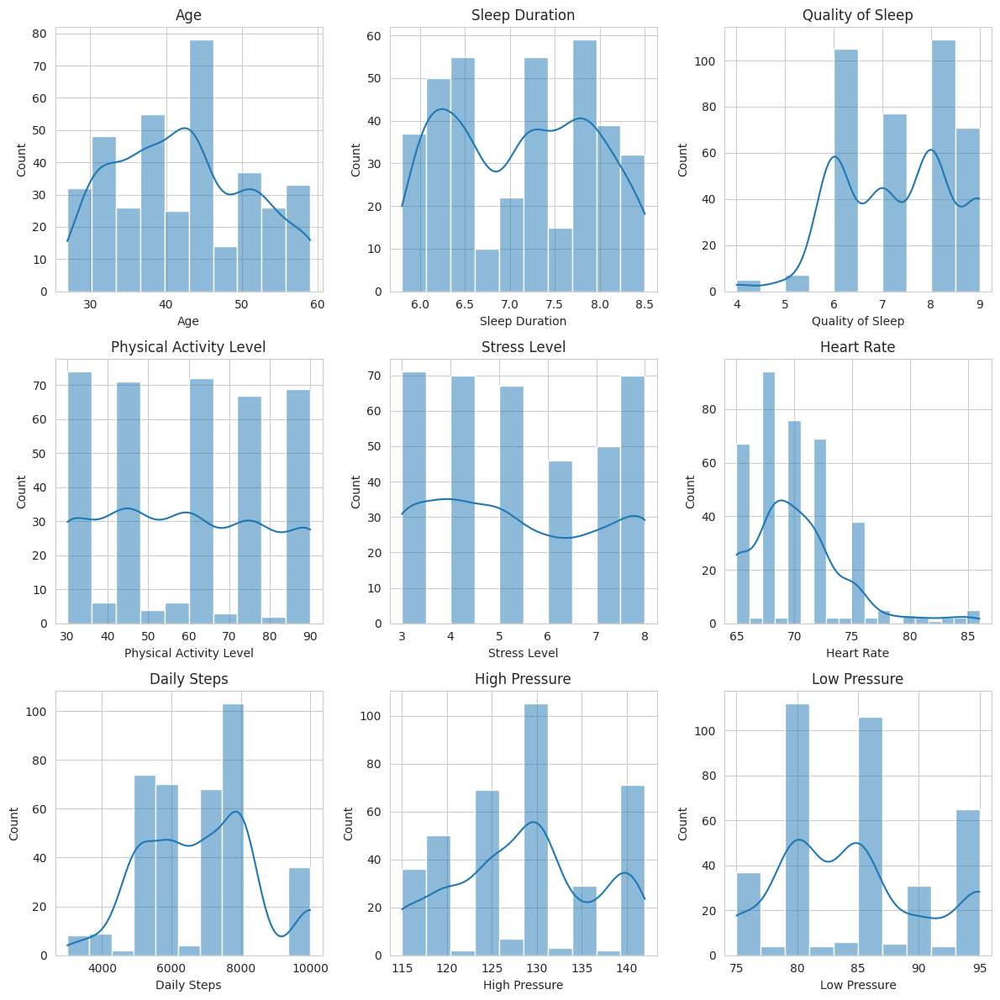

In [ ]:
# Plotting distributions of numerical features
import matplotlib.pyplot as plt # import the module
import seaborn as sns

# Calculate the number of rows and columns for subplots
num_rows = 3  # Changed to 3 rows to accommodate 9 plots
num_cols = 3  # Changed to 3 columns

plt.figure(figsize=(12, 12))  # Adjusted figure size for better layout

for i, col in enumerate(num_col):
    plt.subplot(num_rows, num_cols, i + 1)  # Using num_rows and num_cols
    sns.histplot(df[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

/tmp/ipython-input-1509631051.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipython-input-1509631051.py:23: UserWarning: The palette list has more values (8) than needed (3), which may not be intended.
  sns.boxplot(
/tmp/ipython-input-1509631051.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipython-input-1509631051.py:23: UserWarning: The palette list has more values (8) than needed (3), which may not be intended.
  sns.boxplot(
/tmp/ipython-input-1509631051.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tm

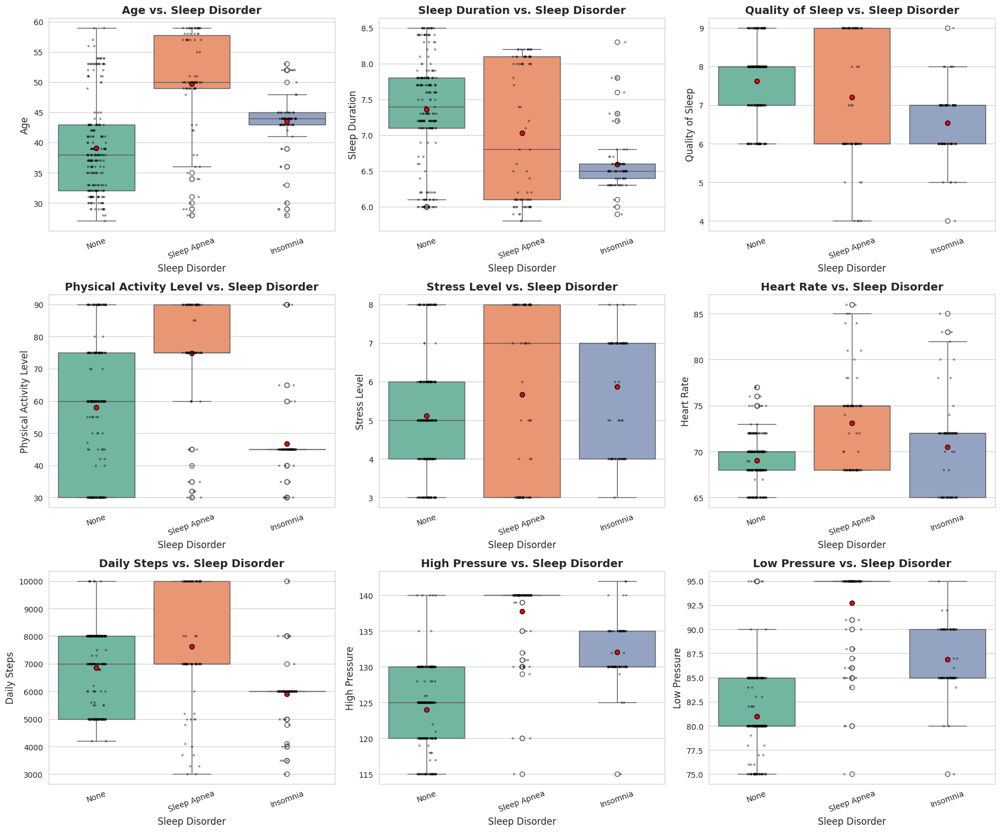

In [ ]:
# ===================== Improved Boxplots: Numerical Features vs. Sleep Disorder =====================
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set seaborn style
sns.set_style("whitegrid")

# Number of numeric features
num_features = len(num_col)
num_cols = 3
num_rows = int(np.ceil(num_features / num_cols))

plt.figure(figsize=(18, num_rows * 5))  # dynamic figure size

# Custom color palette for Sleep Disorder categories
palette = sns.color_palette("Set2")

for i, col in enumerate(num_col):
    plt.subplot(num_rows, num_cols, i + 1)

    # Boxplot with swarm overlay for better distribution view
    sns.boxplot(
        x='Sleep Disorder', y=col, data=df,
        palette=palette, showmeans=True,
        meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"black"}
    )
    sns.stripplot(
        x='Sleep Disorder', y=col, data=df,
        color="black", size=3, alpha=0.4, jitter=True
    )

    # Title and labels
    plt.title(f'{col} vs. Sleep Disorder', fontsize=14, fontweight="bold")
    plt.xlabel("Sleep Disorder", fontsize=12)
    plt.ylabel(col, fontsize=12)
    plt.xticks(rotation=20, fontsize=10)

plt.tight_layout()
plt.show()


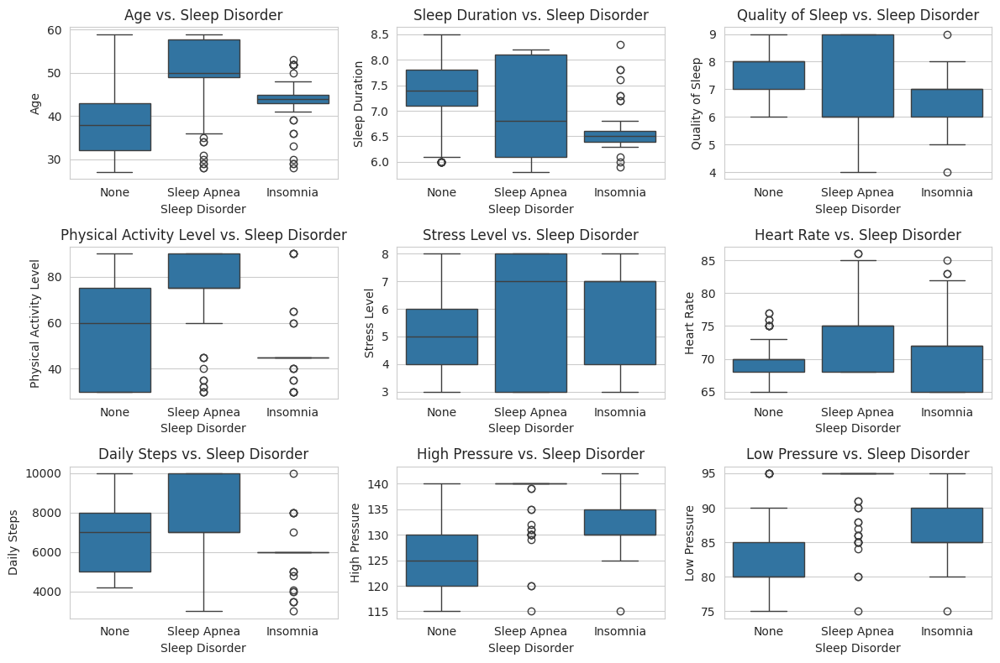

In [ ]:
# Plotting relationships between numerical features and 'Sleep Disorder'
plt.figure(figsize=(12, 8))
# Adjust the subplot layout to accommodate all numerical columns
num_rows = 3  # 3 rows for 9 subplots
num_cols = 3  # 3 columns for 9 subplots
for i, col in enumerate(num_col):
    plt.subplot(num_rows, num_cols, i + 1)  # Updated subplot layout
    sns.boxplot(x='Sleep Disorder', y=col, data=df)
    plt.title(f'{col} vs. Sleep Disorder')
plt.tight_layout()
plt.show()

/tmp/ipython-input-2006771637.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=col, data=df, palette=palette, order=df[col].value_counts().index)
/tmp/ipython-input-2006771637.py:21: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  ax = sns.countplot(x=col, data=df, palette=palette, order=df[col].value_counts().index)
/tmp/ipython-input-2006771637.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=col, data=df, palette=palette, order=df[col].value_counts().index)
/tmp/ipython-input-2006771637.py:21: UserWarning: 
The palette list has fewer values (8) than needed (11) and will cycle, which may produce an uninterpretable 

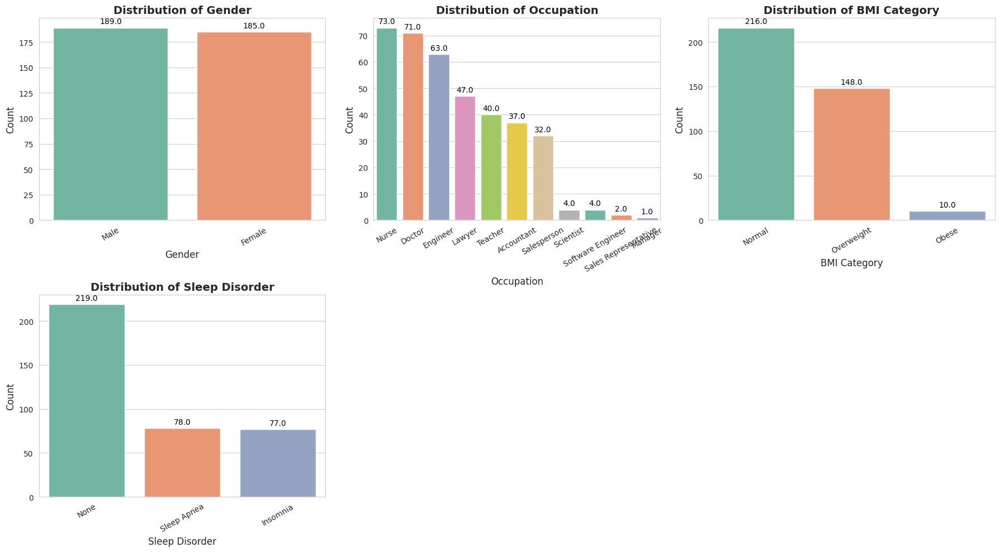

In [ ]:
# ===================== Improved Count Plots for Categorical Features =====================
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_style("whitegrid")

num_features = len(cat_col)
num_cols = 3
num_rows = int(np.ceil(num_features / num_cols))

plt.figure(figsize=(18, num_rows * 5))  # dynamic figure size

# color palette
palette = sns.color_palette("Set2")

for i, col in enumerate(cat_col):
    plt.subplot(num_rows, num_cols, i + 1)

    # Countplot instead of raw bar for better readability
    ax = sns.countplot(x=col, data=df, palette=palette, order=df[col].value_counts().index)

    # Annotate counts on bars
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{height}', (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 3), textcoords='offset points')

    # Titles and labels
    plt.title(f'Distribution of {col}', fontsize=14, fontweight='bold')
    plt.xlabel(col, fontsize=12)
    plt.ylabel("Count", fontsize=12)
    plt.xticks(rotation=30, fontsize=10)

plt.tight_layout()
plt.show()


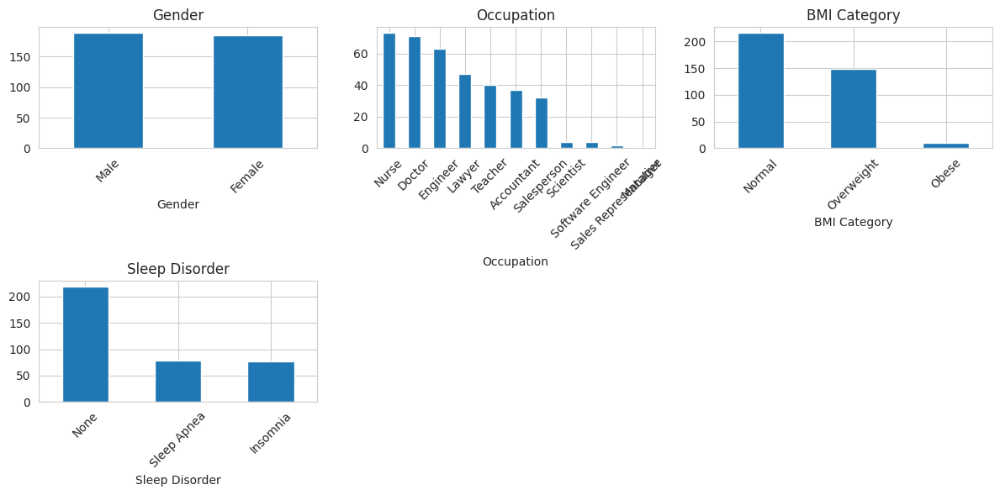

In [ ]:
# Plotting counts of categorical features
plt.figure(figsize=(12, 8))
for i, col in enumerate(cat_col):
    plt.subplot(3, 3, i + 1)
    df[col].value_counts().plot(kind='bar')
    plt.title(col)
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

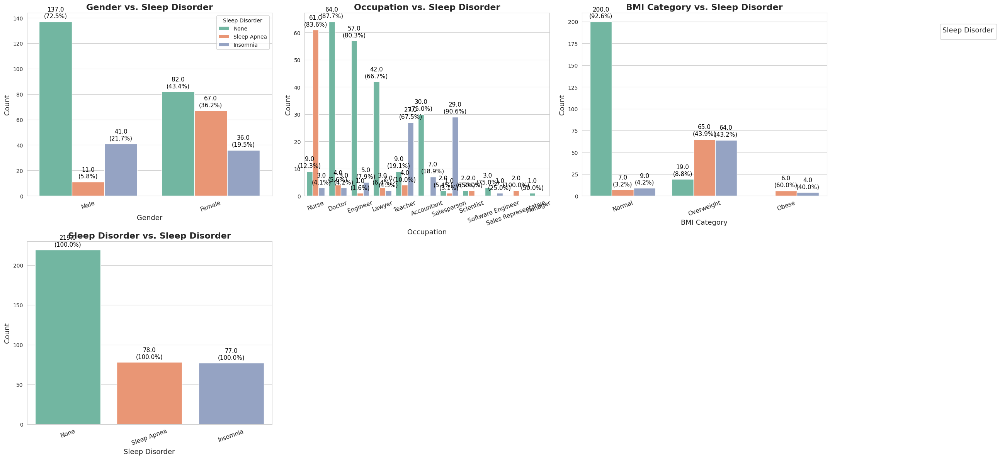

In [ ]:
# ===================== Enhanced Categorical vs. Sleep Disorder Visualization =====================
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_style("whitegrid")

num_features = len(cat_col)
num_cols = 3
num_rows = int(np.ceil(num_features / num_cols))

plt.figure(figsize=(24, num_rows * 6))  # larger figure for clarity

# Custom palette for Sleep Disorder categories
palette = sns.color_palette("Set2", df['Sleep Disorder'].nunique())

for i, col in enumerate(cat_col):
    plt.subplot(num_rows, num_cols, i + 1)

    # Countplot
    ax = sns.countplot(
        x=col, hue='Sleep Disorder', data=df,
        palette=palette, order=df[col].value_counts().index
    )

    # Calculate percentages for annotations
    total_counts = df.groupby(col).size()
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            # Compute % within this category
            group_total = total_counts.loc[p.get_x() + p.get_width()/2] if False else None
            # safer: use group name from xticks
            cat_name = ax.get_xticklabels()[int(p.get_x() + p.get_width()/2)].get_text()
            group_total = total_counts.loc[cat_name]
            percent = 100 * height / group_total
            ax.annotate(f'{height}\n({percent:.1f}%)',
                        (p.get_x() + p.get_width()/2., height),
                        ha='center', va='bottom', fontsize=11,
                        color='black', xytext=(0, 5), textcoords='offset points')

    # Formatting
    plt.title(f"{col} vs. Sleep Disorder", fontsize=16, fontweight="bold")
    plt.xlabel(col, fontsize=13)
    plt.ylabel("Count", fontsize=13)
    plt.xticks(rotation=20, fontsize=11)

    # Hide legends on all except first subplot
    if i != 0:
        plt.legend([],[], frameon=False)

# ✅ Add ONE global legend outside the grid
handles, labels = ax.get_legend_handles_labels()
plt.figlegend(handles, labels, title="Sleep Disorder",
              loc="upper right", bbox_to_anchor=(1.08, 0.95),
              fontsize=12, title_fontsize=13)

plt.tight_layout(rect=[0,0,0.9,1])  # leave space for legend
plt.show()


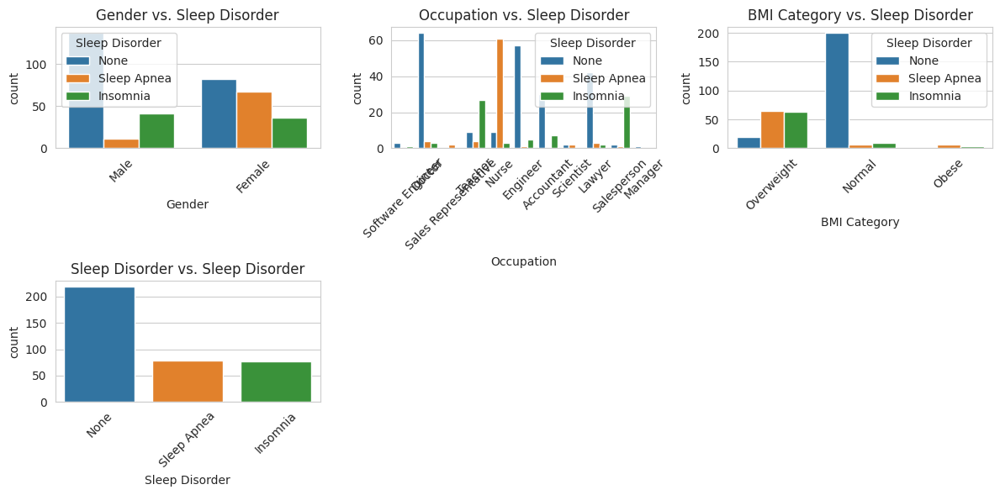

In [ ]:
# Plotting relationships between categorical features and 'Sleep Disorder'
plt.figure(figsize=(12, 8))
for i, col in enumerate(cat_col):
    plt.subplot(3, 3, i + 1)
    sns.countplot(x=col, hue='Sleep Disorder', data=df)
    plt.title(f'{col} vs. Sleep Disorder')
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

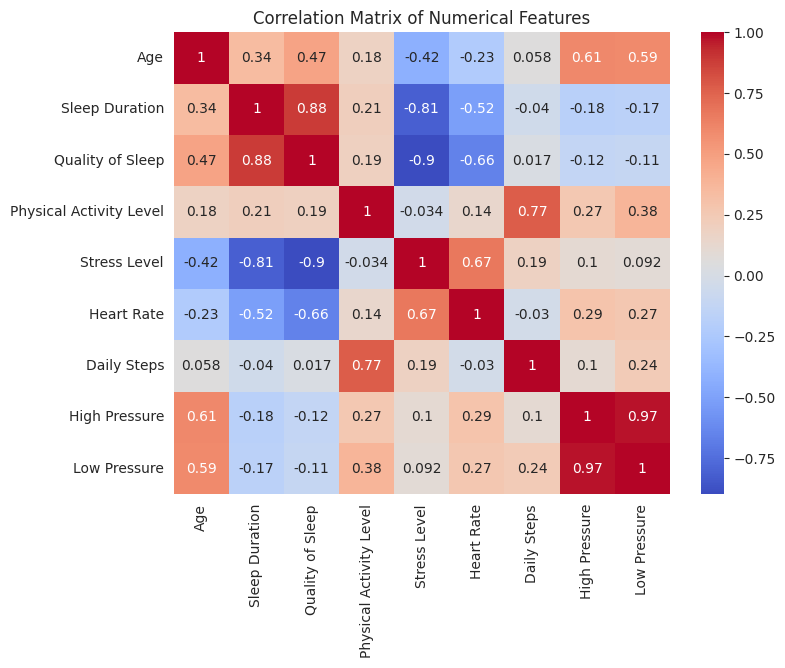

In [ ]:

# Correlation Matrix for numerical features
plt.figure(figsize=(8, 6))
correlation_matrix = df[num_col].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

**Data Visualization**

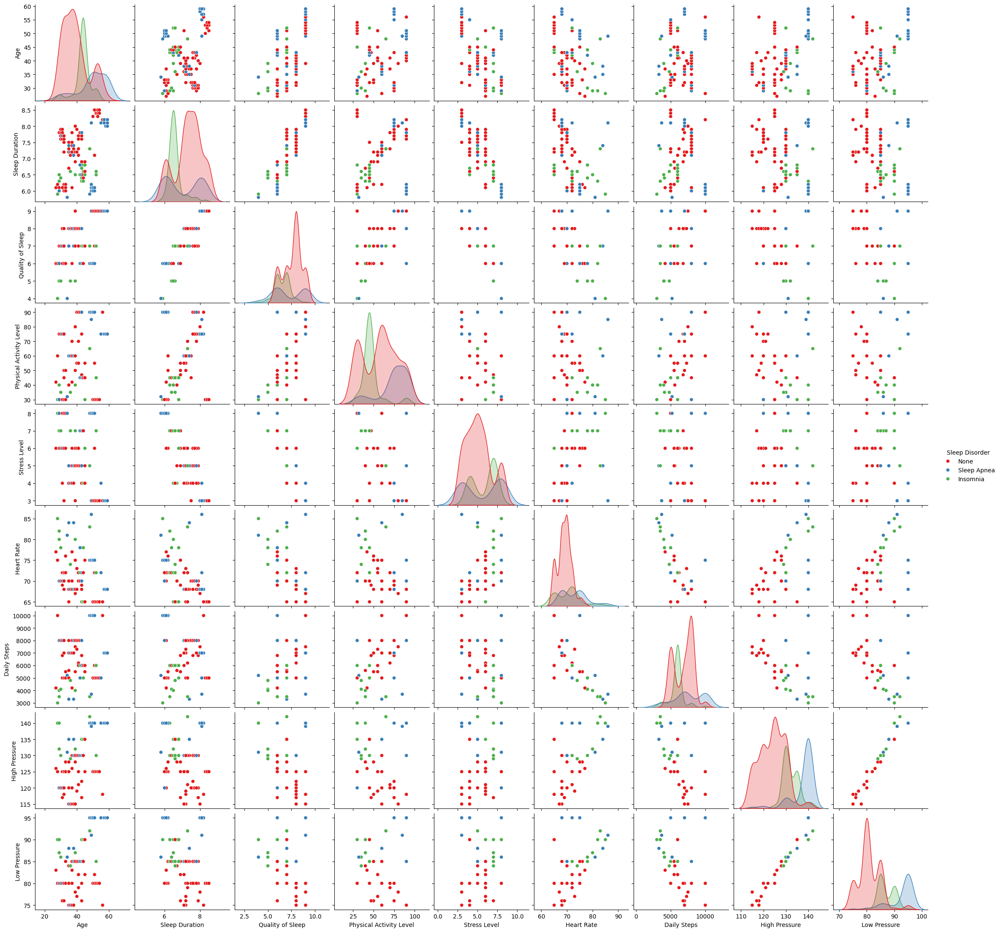

In [ ]:
palette = {'None':''}
sns.pairplot(df, hue='Sleep Disorder', palette='Set1')
plt.show()

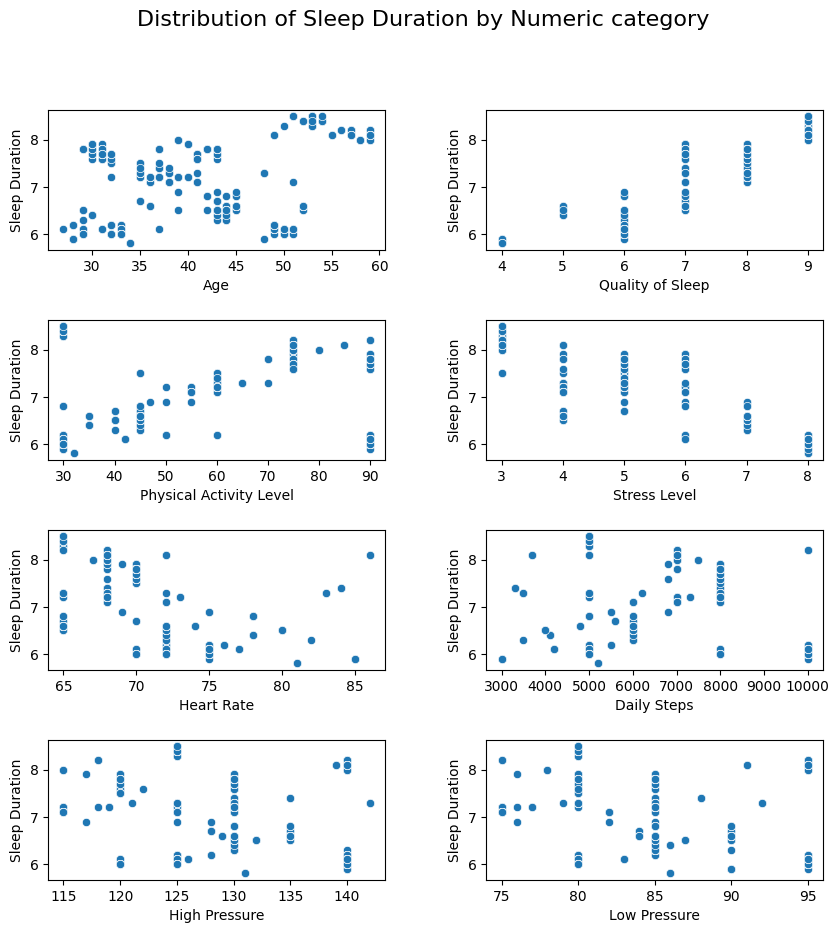

In [ ]:
fig, axs = plt.subplots(4, 2, figsize=(10, 10))
plt.subplots_adjust(wspace=0.3, hspace=0.5)

temp = df[num_col].drop("Sleep Duration", axis=1)
for i, num in enumerate(temp):
    sns.scatterplot(x = df[num], y= df["Sleep Duration"], ax=axs[i // 2, i%2])

fig.suptitle('Distribution of Sleep Duration by Numeric category', fontsize=16)
plt.show()

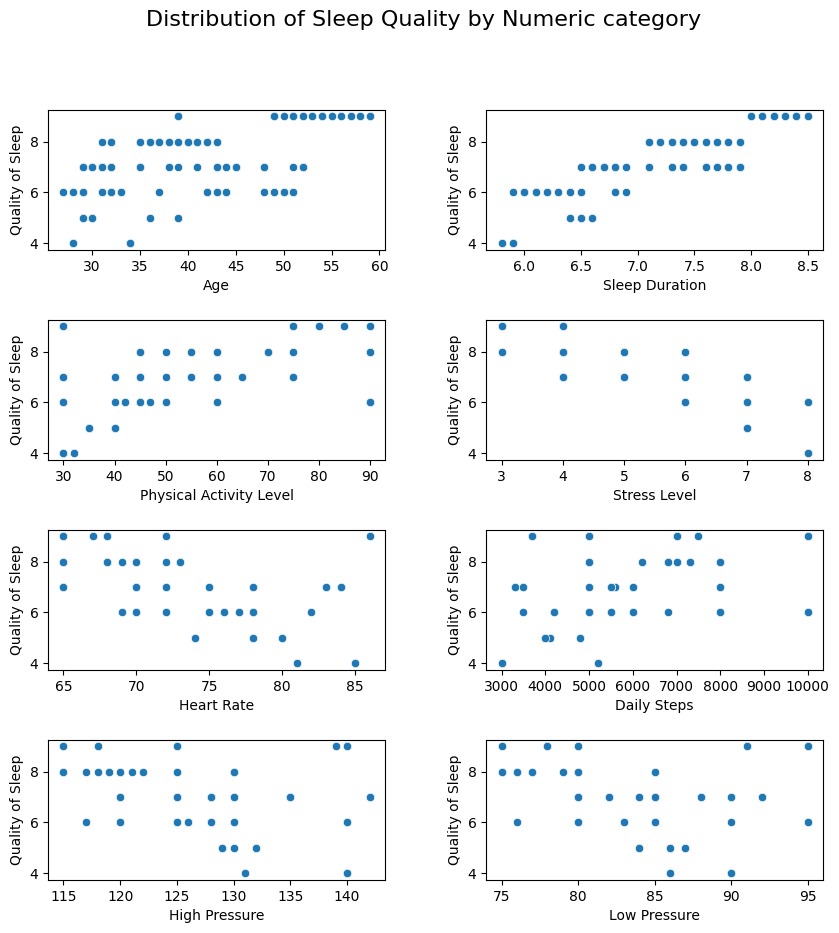

In [ ]:
fig, axs = plt.subplots(4, 2, figsize=(10, 10))
plt.subplots_adjust(wspace=0.3, hspace=0.5)

temp = df[num_col].drop("Quality of Sleep", axis=1)
for i, num in enumerate(temp):
    sns.scatterplot(x = df[num], y= df["Quality of Sleep"], ax=axs[i // 2, i%2])

fig.suptitle('Distribution of Sleep Quality by Numeric category', fontsize=16)
plt.show()

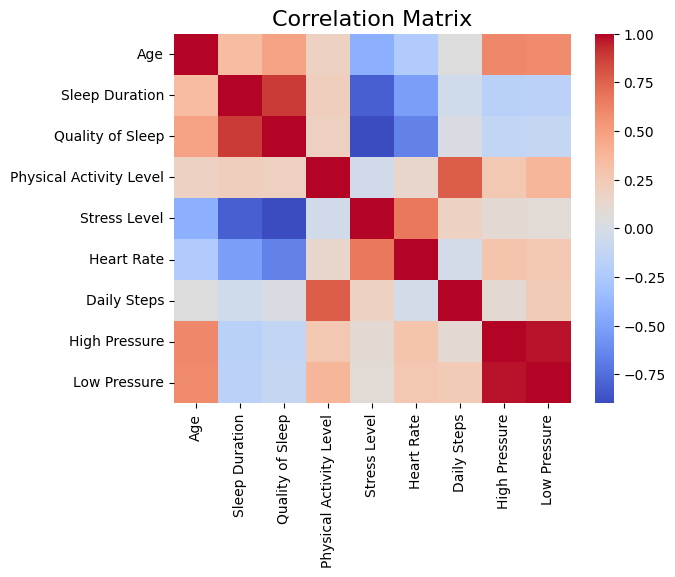

In [ ]:
# Looking closer into correlations to summarize the relationships between variables

corr_matrix = df[num_col].corr()
sns.heatmap(corr_matrix, cmap='coolwarm')
plt.title('Correlation Matrix', fontsize=16)
plt.show()

According to the correletion matrix:

Strong negative correlations between Stress Level and Sleep Duration / Quality of Sleep. As stress level increases, both sleep duration and quality of sleep decrease significantly.

Weak negative correlations between Heart Rate and Sleep Duration / Quality of Sleep; Low Pressure / High Pressure and Sleep Duration / Quality of Sleep; Age and Stress Level; Age and Heart Rate.

Positive correlation between Sleep Duration and Quality of Sleep; Physical Activity Level and Daily Steps. There are direct connections between there pairs. Age and Low Pressure / High Pressure less noticable relations.

Sleep Disorder  Insomnia  None  Sleep Apnea
Gender                                     
Female                36    82           67
Male                  41   137           11 



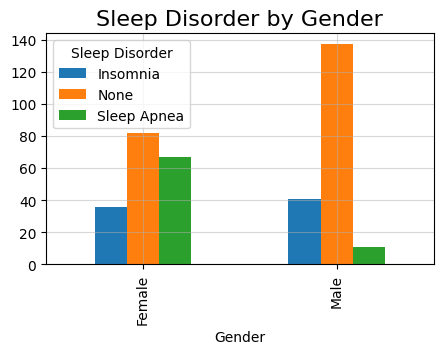

Sleep Disorder        Insomnia  None  Sleep Apnea
Occupation                                       
Accountant                   7    30            0
Doctor                       3    64            4
Engineer                     5    57            1
Lawyer                       2    42            3
Manager                      0     1            0
Nurse                        3     9           61
Sales Representative         0     0            2
Salesperson                 29     2            1
Scientist                    0     2            2
Software Engineer            1     3            0
Teacher                     27     9            4 



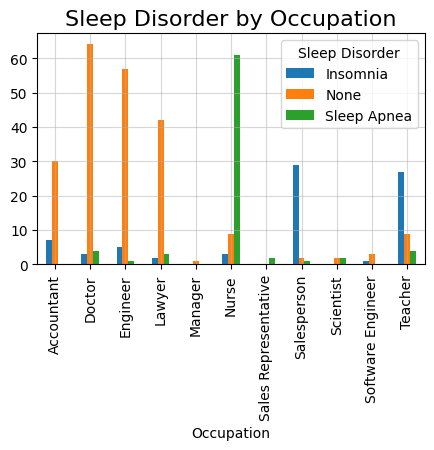

Sleep Disorder  Insomnia  None  Sleep Apnea
BMI Category                               
Normal                 9   200            7
Obese                  4     0            6
Overweight            64    19           65 



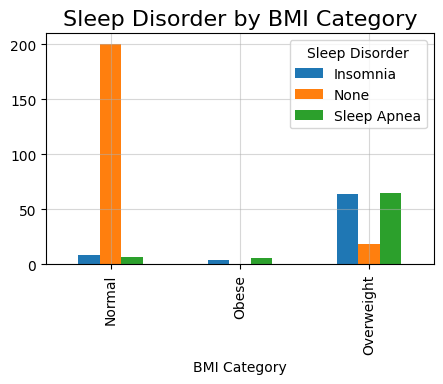

In [ ]:
temp = df[cat_col].drop('Sleep Disorder',axis=1)

for cat in temp:
    cat_slp_dis = df.groupby([cat,'Sleep Disorder'])['Sleep Disorder'].count().unstack(fill_value=0)
    print(cat_slp_dis, '\n')

    cat_slp_dis.plot(kind='bar',figsize=(5, 3))
    plt.grid(alpha=0.5)
    plt.title(f"Sleep Disorder by {cat}", fontsize=16)
    plt.show()

plt.show()

In [ ]:
# prompt: now split this data in 70% for training and 30% for testing

from sklearn.model_selection import train_test_split

# Assuming your DataFrame is named 'df' and 'Sleep Disorder' is your target variable
X = df.drop('Sleep Disorder', axis=1)
y = df['Sleep Disorder']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42) # random_state for reproducibility

# Now you have X_train, X_test, y_train, and y_test
# X_train and y_train are your training data
# X_test and y_test are your testing data

print("Training data shape:", X_train.shape, y_train.shape)
print("Testing data shape:", X_test.shape, y_test.shape)

Training data shape: (261, 12) (261,)
Testing data shape: (113, 12) (113,)


**modelling**

In [ ]:
# prompt: apply 20  machine learning algorithms for accuracy, and confusion matrix of training and testing

from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
import lightgbm as lgb
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.gaussian_process import GaussianProcessClassifier

# ... (Your existing code) ...

# Convert categorical columns to numerical using Label Encoding
le = LabelEncoder()
# Exclude 'Sleep Disorder' from the columns to be encoded
for col in cat_col:
    if col != 'Sleep Disorder':  # Add this condition
        X_train[col] = le.fit_transform(X_train[col])
        X_test[col] = le.transform(X_test[col])

# Encode the target variable 'y'
y_train = le.fit_transform(y_train)  # Encode y_train
y_test = le.transform(y_test)  # Encode y_test

# Scale numerical features
scaler = StandardScaler()
X_train[num_col] = scaler.fit_transform(X_train[num_col])
X_test[num_col] = scaler.transform(X_test[num_col])


# 20 Machine Learning Algorithms
models = [
    LogisticRegression(),
    KNeighborsClassifier(),
    SVC(),
    DecisionTreeClassifier(),
    RandomForestClassifier(),
    GradientBoostingClassifier(),
    AdaBoostClassifier(),
    GaussianNB(),
    LinearDiscriminantAnalysis(),
    QuadraticDiscriminantAnalysis(),
    MLPClassifier(),
    XGBClassifier(),
    lgb.LGBMClassifier(),
    BaggingClassifier(),
    ExtraTreesClassifier(),
    GaussianProcessClassifier(),
]

for model in models:
    model_name = model.__class__.__name__
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    train_accuracy = accuracy_score(y_train, y_pred_train)
    test_accuracy = accuracy_score(y_test, y_pred_test)

    train_cm = confusion_matrix(y_train, y_pred_train)
    test_cm = confusion_matrix(y_test, y_pred_test)
    print(f"{model_name} - Training Accuracy: {train_accuracy:.4f}")
    print(f"{model_name} - Testing Accuracy: {test_accuracy:.4f}")
    print(f"{model_name} - Training Confusion Matrix:\n{train_cm}")
    print(f"{model_name} - Testing Confusion Matrix:\n{test_cm}\n")

Training LogisticRegression...
LogisticRegression - Training Accuracy: 0.9195
LogisticRegression - Testing Accuracy: 0.8938
LogisticRegression - Training Confusion Matrix:
[[ 46   7   0]
 [  4 148   5]
 [  2   3  46]]
LogisticRegression - Testing Confusion Matrix:
[[21  2  1]
 [ 3 59  0]
 [ 2  4 21]]

Training KNeighborsClassifier...
KNeighborsClassifier - Training Accuracy: 0.9004
KNeighborsClassifier - Testing Accuracy: 0.8850
KNeighborsClassifier - Training Confusion Matrix:
[[ 44   7   2]
 [  7 145   5]
 [  2   3  46]]
KNeighborsClassifier - Testing Confusion Matrix:
[[20  2  2]
 [ 2 60  0]
 [ 5  2 20]]

Training SVC...
SVC - Training Accuracy: 0.9157
SVC - Testing Accuracy: 0.8761
SVC - Training Confusion Matrix:
[[ 47   5   1]
 [  7 145   5]
 [  1   3  47]]
SVC - Testing Confusion Matrix:
[[20  2  2]
 [ 3 59  0]
 [ 5  2 20]]

Training DecisionTreeClassifier...
DecisionTreeClassifier - Training Accuracy: 0.9349
DecisionTreeClassifier - Testing Accuracy: 0.8761
DecisionTreeClassifi

/usr/local/lib/python3.12/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 2 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier - Training Accuracy: 0.9310
MLPClassifier - Testing Accuracy: 0.9204
MLPClassifier - Training Confusion Matrix:
[[ 47   5   1]
 [  3 149   5]
 [  1   3  47]]
MLPClassifier - Testing Confusion Matrix:
[[20  2  2]
 [ 1 61  0]
 [ 2  2 23]]

Training XGBClassifier...
XGBClassifier - Training Accuracy: 0.9349
XGBClassifier - Testing Accuracy: 0.8938
XGBClassifier - Training Confusion Matrix:
[[ 48   5   0]
 [  3 149   5]
 [  1   3  47]]
XGBClassifier - Testing Confusion Matrix:
[[20  2  2]
 [ 1 61  0]
 [ 5  2 20]]

Training LGBMClassifier...
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000032 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 141
[LightGBM] [Info] Number of data points in the train set: 261, number of used features: 12
[LightGBM] [I

In [ ]:
!pip install catboost
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, StackingClassifier, VotingClassifier, HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
import lightgbm as lgb
from sklearn.ensemble import BaggingClassifier, ExtraTreesClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from catboost import CatBoostClassifier
# Removed the following imports as they are not used for classification
# from sklearn.kernel_ridge import KernelRidge
# from sklearn.ensemble import IsolationForest
# from sklearn.cluster import KMeans
# from sklearn.semi_supervised import LabelPropagation, LabelSpreading

# ... (Your existing code) ...

# Convert categorical columns to numerical using Label Encoding
le = LabelEncoder()
# Exclude 'Sleep Disorder' from the columns to be encoded
for col in cat_col:
    if col != 'Sleep Disorder':  # Add this condition
        X_train[col] = le.fit_transform(X_train[col])
        X_test[col] = le.transform(X_test[col])

# Scale numerical features
scaler = StandardScaler()
X_train[num_col] = scaler.fit_transform(X_train[num_col])
X_test[num_col] = scaler.transform(X_test[num_col])

# 30 Machine Learning Algorithms - Updated
# Removed models not suitable for classification: KernelRidge, IsolationForest, KMeans, LabelPropagation, LabelSpreading
models = [
    LogisticRegression(),
    KNeighborsClassifier(),
    SVC(),
    DecisionTreeClassifier(),
    RandomForestClassifier(),
    GradientBoostingClassifier(),
    AdaBoostClassifier(),
    GaussianNB(),
    LinearDiscriminantAnalysis(),
    QuadraticDiscriminantAnalysis(),
    MLPClassifier(),
    XGBClassifier(),
    lgb.LGBMClassifier(),
    BaggingClassifier(),
    ExtraTreesClassifier(),
    GaussianProcessClassifier(),
    RidgeClassifier(),
    SGDClassifier(),
    CatBoostClassifier(verbose=0),
    HistGradientBoostingClassifier(),
    StackingClassifier(estimators=[('rf', RandomForestClassifier()), ('gb', GradientBoostingClassifier())], final_estimator=LogisticRegression()),
    VotingClassifier(estimators=[('rf', RandomForestClassifier()), ('svc', SVC()), ('gb', GradientBoostingClassifier())], voting='hard'),
]

for model in models:
    model_name = model.__class__.__name__
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    train_accuracy = accuracy_score(y_train, y_pred_train)
    test_accuracy = accuracy_score(y_test, y_pred_test)

    train_cm = confusion_matrix(y_train, y_pred_train)
    test_cm = confusion_matrix(y_test, y_pred_test)
    print(f"{model_name} - Training Accuracy: {train_accuracy:.4f}")
    print(f"{model_name} - Testing Accuracy: {test_accuracy:.4f}")
    print(f"{model_name} - Training Confusion Matrix:\n{train_cm}")
    print(f"{model_name} - Testing Confusion Matrix:\n{test_cm}\n")

Training LogisticRegression...
LogisticRegression - Training Accuracy: 0.9195
LogisticRegression - Testing Accuracy: 0.8938
LogisticRegression - Training Confusion Matrix:
[[ 46   7   0]
 [  4 148   5]
 [  2   3  46]]
LogisticRegression - Testing Confusion Matrix:
[[21  2  1]
 [ 3 59  0]
 [ 2  4 21]]

Training KNeighborsClassifier...
KNeighborsClassifier - Training Accuracy: 0.9004
KNeighborsClassifier - Testing Accuracy: 0.8850
KNeighborsClassifier - Training Confusion Matrix:
[[ 44   7   2]
 [  7 145   5]
 [  2   3  46]]
KNeighborsClassifier - Testing Confusion Matrix:
[[20  2  2]
 [ 2 60  0]
 [ 5  2 20]]

Training SVC...
SVC - Training Accuracy: 0.9157
SVC - Testing Accuracy: 0.8761
SVC - Training Confusion Matrix:
[[ 47   5   1]
 [  7 145   5]
 [  1   3  47]]
SVC - Testing Confusion Matrix:
[[20  2  2]
 [ 3 59  0]
 [ 5  2 20]]

Training DecisionTreeClassifier...
DecisionTreeClassifier - Training Accuracy: 0.9349
DecisionTreeClassifier - Testing Accuracy: 0.8673
DecisionTreeClassifi

/usr/local/lib/python3.12/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 2 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier - Training Accuracy: 0.9272
MLPClassifier - Testing Accuracy: 0.9204
MLPClassifier - Training Confusion Matrix:
[[ 47   5   1]
 [  3 149   5]
 [  2   3  46]]
MLPClassifier - Testing Confusion Matrix:
[[21  2  1]
 [ 1 61  0]
 [ 3  2 22]]

Training XGBClassifier...
XGBClassifier - Training Accuracy: 0.9349
XGBClassifier - Testing Accuracy: 0.8938
XGBClassifier - Training Confusion Matrix:
[[ 48   5   0]
 [  3 149   5]
 [  1   3  47]]
XGBClassifier - Testing Confusion Matrix:
[[20  2  2]
 [ 1 61  0]
 [ 5  2 20]]

Training LGBMClassifier...
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000026 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 141
[LightGBM] [Info] Number of data points in the train set: 261, number of used features: 12
[LightGBM] [I

hyperparameter tuning

In [ ]:
!pip install catboost
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, StackingClassifier, VotingClassifier, HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
import lightgbm as lgb
from sklearn.ensemble import BaggingClassifier, ExtraTreesClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.exceptions import NotFittedError

# Convert categorical columns to numerical using Label Encoding
le = LabelEncoder()
for col in cat_col:
    if col != 'Sleep Disorder':
        X_train[col] = le.fit_transform(X_train[col])
        X_test[col] = le.transform(X_test[col])

# Scale numerical features
scaler = StandardScaler()
X_train[num_col] = scaler.fit_transform(X_train[num_col])
X_test[num_col] = scaler.transform(X_test[num_col])

# 20 Machine Learning Algorithms with Hyperparameter Tuning
models_with_params = [
    (LogisticRegression(), {'C': [0.1, 1, 10]}),
    (KNeighborsClassifier(), {'n_neighbors': [3, 5, 7]}),
    (SVC(), {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}),
    (DecisionTreeClassifier(), {'max_depth': [5, 10, 20]}),
    (RandomForestClassifier(), {'n_estimators': [100, 200], 'max_depth': [5, 10, None]}),
    (GradientBoostingClassifier(), {'learning_rate': [0.01, 0.1], 'n_estimators': [100, 200]}),
    (AdaBoostClassifier(), {'n_estimators': [50, 100]}),
    (GaussianNB(), {}),
    (LinearDiscriminantAnalysis(), {}),
    (QuadraticDiscriminantAnalysis(), {}),
    (MLPClassifier(), {'hidden_layer_sizes': [(100,), (50, 50)], 'alpha': [0.0001, 0.001]}),
    (XGBClassifier(), {'learning_rate': [0.01, 0.1], 'max_depth': [3, 5]}),
    (lgb.LGBMClassifier(), {'learning_rate': [0.01, 0.1], 'n_estimators': [100, 200]}),
    (BaggingClassifier(), {'n_estimators': [10, 50]}),
    (ExtraTreesClassifier(), {'n_estimators': [100, 200]}),
    (GaussianProcessClassifier(), {}),
    (RidgeClassifier(), {'alpha': [0.1, 1, 10]}),
    (SGDClassifier(), {'alpha': [0.0001, 0.001], 'penalty': ['l2', 'elasticnet']}),
    (CatBoostClassifier(verbose=0), {'learning_rate': [0.01, 0.1], 'depth': [6, 8]}),
    (HistGradientBoostingClassifier(), {'learning_rate': [0.01, 0.1], 'max_iter': [100, 200]})
]

# Perform GridSearchCV for hyperparameter tuning and evaluate each model
for model, params in models_with_params:
    model_name = model.__class__.__name__
    try:
        print(f"Tuning {model_name}...")
        grid = GridSearchCV(model, params, cv=3, scoring='accuracy', verbose=2, n_jobs=-1)
        grid.fit(X_train, y_train)
        best_model = grid.best_estimator_
    except (AttributeError, TypeError, ValueError, NotFittedError) as e:
        print(f"GridSearchCV not supported for {model_name} due to: {e}")
        best_model = model.fit(X_train, y_train)

    # Evaluate the model
    y_pred_train = best_model.predict(X_train)
    y_pred_test = best_model.predict(X_test)

    train_accuracy = accuracy_score(y_train, y_pred_train)
    test_accuracy = accuracy_score(y_test, y_pred_test)

    train_cm = confusion_matrix(y_train, y_pred_train)
    test_cm = confusion_matrix(y_test, y_pred_test)

    print(f"{model_name} - Training Accuracy: {train_accuracy:.4f}")
    print(f"{model_name} - Testing Accuracy: {test_accuracy:.4f}")
    print(f"{model_name} - Training Confusion Matrix:\n{train_cm}")
    print(f"{model_name} - Testing Confusion Matrix:\n{test_cm}\n")


Tuning LogisticRegression...
Fitting 3 folds for each of 3 candidates, totalling 9 fits


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression - Training Accuracy: 0.9234
LogisticRegression - Testing Accuracy: 0.9204
LogisticRegression - Training Confusion Matrix:
[[ 46   6   1]
 [  3 149   5]
 [  2   3  46]]
LogisticRegression - Testing Confusion Matrix:
[[21  2  1]
 [ 1 61  0]
 [ 2  3 22]]

Tuning KNeighborsClassifier...
Fitting 3 folds for each of 3 candidates, totalling 9 fits
KNeighborsClassifier - Training Accuracy: 0.9004
KNeighborsClassifier - Testing Accuracy: 0.8850
KNeighborsClassifier - Training Confusion Matrix:
[[ 44   7   2]
 [  7 145   5]
 [  2   3  46]]
KNeighborsClassifier - Testing Confusion Matrix:
[[20  2  2]
 [ 2 60  0]
 [ 5  2 20]]

Tuning SVC...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
SVC - Training Accuracy: 0.9272
SVC - Testing Accuracy: 0.9115
SVC - Training Confusion Matrix:
[[ 48   5   0]
 [  4 148   5]
 [  2   3  46]]
SVC - Testing Confusion Matrix:
[[21  2  1]
 [ 1 61  0]
 [ 4  2 21]]

Tuning DecisionTreeClassifier...
Fitting 3 folds for each of 3 candidate

/usr/local/lib/python3.12/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 2 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier - Training Accuracy: 0.9349
MLPClassifier - Testing Accuracy: 0.9115
MLPClassifier - Training Confusion Matrix:
[[ 48   5   0]
 [  3 149   5]
 [  1   3  47]]
MLPClassifier - Testing Confusion Matrix:
[[21  2  1]
 [ 1 61  0]
 [ 4  2 21]]

Tuning XGBClassifier...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
XGBClassifier - Training Accuracy: 0.9349
XGBClassifier - Testing Accuracy: 0.8938
XGBClassifier - Training Confusion Matrix:
[[ 48   5   0]
 [  3 149   5]
 [  1   3  47]]
XGBClassifier - Testing Confusion Matrix:
[[20  2  2]
 [ 1 61  0]
 [ 5  2 20]]

Tuning LGBMClassifier...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000038 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Tot

In [ ]:
!pip install catboost
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier, VotingClassifier, HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
import lightgbm as lgb
from sklearn.ensemble import BaggingClassifier, ExtraTreesClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.exceptions import NotFittedError

# Convert categorical columns to numerical using Label Encoding
le = LabelEncoder()
for col in cat_col:
    if col != 'Sleep Disorder':
        X_train[col] = le.fit_transform(X_train[col])
        X_test[col] = le.transform(X_test[col])

# Scale numerical features
scaler = StandardScaler()
X_train[num_col] = scaler.fit_transform(X_train[num_col])
X_test[num_col] = scaler.transform(X_test[num_col])

# 16 Machine Learning Algorithms with Hyperparameter Tuning (AdaBoost, LDA, Ridge, SGD removed)
models_with_params = [
    (LogisticRegression(), {'C': [0.1, 1, 10]}),
    (KNeighborsClassifier(), {'n_neighbors': [3, 5, 7]}),
    (SVC(), {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}),
    (DecisionTreeClassifier(), {'max_depth': [5, 10, 20]}),
    (RandomForestClassifier(), {'n_estimators': [100, 200], 'max_depth': [5, 10, None]}),
    (GradientBoostingClassifier(), {'learning_rate': [0.01, 0.1], 'n_estimators': [100, 200]}),
    (GaussianNB(), {}),
    (QuadraticDiscriminantAnalysis(), {}),
    (MLPClassifier(), {'hidden_layer_sizes': [(100,), (50, 50)], 'alpha': [0.0001, 0.001]}),
    (XGBClassifier(), {'learning_rate': [0.01, 0.1], 'max_depth': [3, 5]}),
    (lgb.LGBMClassifier(), {'learning_rate': [0.01, 0.1], 'n_estimators': [100, 200]}),
    (BaggingClassifier(), {'n_estimators': [10, 50]}),
    (ExtraTreesClassifier(), {'n_estimators': [100, 200]}),
    (GaussianProcessClassifier(), {}),
    (CatBoostClassifier(verbose=0), {'learning_rate': [0.01, 0.1], 'depth': [6, 8]}),
    (HistGradientBoostingClassifier(), {'learning_rate': [0.01, 0.1], 'max_iter': [100, 200]})
]

# Perform GridSearchCV for hyperparameter tuning and evaluate each model
for model, params in models_with_params:
    model_name = model.__class__.__name__
    try:
        print(f"Tuning {model_name}...")
        grid = GridSearchCV(model, params, cv=3, scoring='accuracy', verbose=2, n_jobs=-1)
        grid.fit(X_train, y_train)
        best_model = grid.best_estimator_
    except (AttributeError, TypeError, ValueError, NotFittedError) as e:
        print(f"GridSearchCV not supported for {model_name} due to: {e}")
        best_model = model.fit(X_train, y_train)

    # Evaluate the model
    y_pred_train = best_model.predict(X_train)
    y_pred_test = best_model.predict(X_test)

    train_accuracy = accuracy_score(y_train, y_pred_train)
    test_accuracy = accuracy_score(y_test, y_pred_test)

    train_cm = confusion_matrix(y_train, y_pred_train)
    test_cm = confusion_matrix(y_test, y_pred_test)

    print(f"{model_name} - Training Accuracy: {train_accuracy:.4f}")
    print(f"{model_name} - Testing Accuracy: {test_accuracy:.4f}")
    print(f"{model_name} - Training Confusion Matrix:\n{train_cm}")
    print(f"{model_name} - Testing Confusion Matrix:\n{test_cm}\n")


Tuning LogisticRegression...
Fitting 3 folds for each of 3 candidates, totalling 9 fits


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression - Training Accuracy: 0.9234
LogisticRegression - Testing Accuracy: 0.9204
LogisticRegression - Training Confusion Matrix:
[[ 46   6   1]
 [  3 149   5]
 [  2   3  46]]
LogisticRegression - Testing Confusion Matrix:
[[21  2  1]
 [ 1 61  0]
 [ 2  3 22]]

Tuning KNeighborsClassifier...
Fitting 3 folds for each of 3 candidates, totalling 9 fits
KNeighborsClassifier - Training Accuracy: 0.9004
KNeighborsClassifier - Testing Accuracy: 0.8850
KNeighborsClassifier - Training Confusion Matrix:
[[ 44   7   2]
 [  7 145   5]
 [  2   3  46]]
KNeighborsClassifier - Testing Confusion Matrix:
[[20  2  2]
 [ 2 60  0]
 [ 5  2 20]]

Tuning SVC...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
SVC - Training Accuracy: 0.9272
SVC - Testing Accuracy: 0.9115
SVC - Training Confusion Matrix:
[[ 48   5   0]
 [  4 148   5]
 [  2   3  46]]
SVC - Testing Confusion Matrix:
[[21  2  1]
 [ 1 61  0]
 [ 4  2 21]]

Tuning DecisionTreeClassifier...
Fitting 3 folds for each of 3 candidate

/usr/local/lib/python3.12/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 2 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier - Training Accuracy: 0.9310
MLPClassifier - Testing Accuracy: 0.9115
MLPClassifier - Training Confusion Matrix:
[[ 48   5   0]
 [  3 149   5]
 [  2   3  46]]
MLPClassifier - Testing Confusion Matrix:
[[21  2  1]
 [ 1 61  0]
 [ 4  2 21]]

Tuning XGBClassifier...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
XGBClassifier - Training Accuracy: 0.9349
XGBClassifier - Testing Accuracy: 0.8938
XGBClassifier - Training Confusion Matrix:
[[ 48   5   0]
 [  3 149   5]
 [  1   3  47]]
XGBClassifier - Testing Confusion Matrix:
[[20  2  2]
 [ 1 61  0]
 [ 5  2 20]]

Tuning LGBMClassifier...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000047 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Tot

Federated Learning

In [ ]:
# ===================== Federated Learning (Simulation) on Your Pipeline =====================
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.base import BaseEstimator, ClassifierMixin, clone

# --- Ensure SVC has probabilities for aggregation ---
#   (We keep your list but set probability=True for SVC)
models_with_params_fl = [
    (LogisticRegression(), {'C': [0.1, 1, 10]}),
    (KNeighborsClassifier(), {'n_neighbors': [3, 5, 7]}),
    (SVC(probability=True), {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}),
    (DecisionTreeClassifier(), {'max_depth': [5, 10, 20]}),
    (RandomForestClassifier(), {'n_estimators': [100, 200], 'max_depth': [5, 10, None]}),
    (GradientBoostingClassifier(), {'learning_rate': [0.01, 0.1], 'n_estimators': [100, 200]}),
    (GaussianNB(), {}),
    (QuadraticDiscriminantAnalysis(), {}),
    (MLPClassifier(), {'hidden_layer_sizes': [(100,), (50, 50)], 'alpha': [0.0001, 0.001]}),
    (XGBClassifier(use_label_encoder=False, eval_metric='logloss'),
        {'learning_rate': [0.01, 0.1], 'max_depth': [3, 5]}),
    (lgb.LGBMClassifier(), {'learning_rate': [0.01, 0.1], 'n_estimators': [100, 200]}),
    (BaggingClassifier(), {'n_estimators': [10, 50]}),
    (ExtraTreesClassifier(), {'n_estimators': [100, 200]}),
    (GaussianProcessClassifier(), {}),
    (CatBoostClassifier(verbose=0), {'learning_rate': [0.01, 0.1], 'depth': [6, 8]}),
    (HistGradientBoostingClassifier(), {'learning_rate': [0.01, 0.1], 'max_iter': [100, 200]})
]

# -------- utilities: robust array conversion (works for DataFrame or ndarray) --------
def to_numpy(X):
    return X.values if hasattr(X, "values") else X

def get_classes(y):
    y_np = to_numpy(y)
    return np.unique(y_np)

# -------- client partition: each client gets one stratified fold (disjoint) --------
def make_clients(X, y, n_clients=5, random_state=42):
    X_np, y_np = to_numpy(X), to_numpy(y)
    skf = StratifiedKFold(n_splits=n_clients, shuffle=True, random_state=random_state)
    splits = []
    for _, client_idx in skf.split(X_np, y_np):
        splits.append((X_np[client_idx].copy(), y_np[client_idx].copy()))
    return splits

# -------- fit on a single client with GridSearch (if params) else plain fit --------
def fit_on_client(model, params, Xc, yc):
    try:
        if params:
            grid = GridSearchCV(model, params, cv=3, scoring='accuracy', n_jobs=-1, verbose=0)
            grid.fit(Xc, yc)
            return grid.best_estimator_
        else:
            m = clone(model)
            m.fit(Xc, yc)
            return m
    except Exception:
        m = clone(model)
        m.fit(Xc, yc)
        return m

# -------- Global aggregator (probability averaging with client-size weights) --------
class GlobalAggregator(BaseEstimator, ClassifierMixin):
    def __init__(self, client_models, classes_, client_weights=None):
        self.client_models = client_models
        self.classes_ = np.array(classes_)
        if client_weights is None:
            self.client_weights = np.ones(len(client_models), dtype=float)
        else:
            self.client_weights = np.array(client_weights, dtype=float)
            self.client_weights = self.client_weights / (self.client_weights.sum() + 1e-12)

    def _align_proba(self, p, model_classes):
        aligned = np.zeros((p.shape[0], len(self.classes_)))
        for i, c in enumerate(self.classes_):
            if c in model_classes:
                idx = list(model_classes).index(c)
                aligned[:, i] = p[:, idx]
        return aligned

    def predict_proba(self, X):
        X_np = to_numpy(X)
        prob_sum = np.zeros((X_np.shape[0], len(self.classes_)))
        for w, m in zip(self.client_weights, self.client_models):
            if hasattr(m, "predict_proba"):
                p = m.predict_proba(X_np)
                mc = getattr(m, "classes_", self.classes_)
                aligned = self._align_proba(p, mc)
            elif hasattr(m, "decision_function"):
                df = m.decision_function(X_np)
                if df.ndim == 1:  # binary
                    p1 = 1 / (1 + np.exp(-df))
                    p = np.vstack([1 - p1, p1]).T
                else:             # multi-class softmax
                    e = np.exp(df - df.max(axis=1, keepdims=True))
                    p = e / (e.sum(axis=1, keepdims=True) + 1e-12)
                mc = getattr(m, "classes_", self.classes_)
                aligned = self._align_proba(p, mc)
            else:
                yhat = m.predict(X_np)
                p = np.zeros((len(yhat), len(self.classes_)))
                for i, c in enumerate(self.classes_):
                    p[:, i] = (yhat == c).astype(float)
                aligned = p
            prob_sum += w * aligned
        # normalize row-wise in case of numeric drift
        prob_sum = np.clip(prob_sum, 1e-12, None)
        prob_sum = prob_sum / prob_sum.sum(axis=1, keepdims=True)
        return prob_sum

    def predict(self, X):
        p = self.predict_proba(X)
        idx = np.argmax(p, axis=1)
        return self.classes_[idx]

# ----------------------- RUN FL per algorithm & pick best -----------------------
n_clients = 5            # change if needed
clients = make_clients(X_train, y_train, n_clients=n_clients, random_state=42)
classes_ = get_classes(y_train)

summary = []
global_models = {}   # name -> GlobalAggregator

for base_model, params in models_with_params_fl:
    name = base_model.__class__.__name__
    print(f"\n========== Federated training: {name} ==========")
    client_models, client_sizes = [], []

    # Local training on each client
    for ci, (Xc, yc) in enumerate(clients, start=1):
        m = fit_on_client(base_model, params, Xc, yc)
        client_models.append(m)
        client_sizes.append(len(yc))
        try:
            tr_acc = accuracy_score(yc, m.predict(Xc))
            print(f"  Client {ci}: n={len(yc)} | local train acc = {tr_acc:.3f}")
        except Exception:
            print(f"  Client {ci}: n={len(yc)} | local model fitted")

    # Build weighted global aggregator
    gmodel = GlobalAggregator(client_models, classes_=classes_, client_weights=client_sizes)
    global_models[name] = gmodel

    # Evaluate global model
    y_pred_train_g = gmodel.predict(X_train)
    y_pred_test_g  = gmodel.predict(X_test)

    train_acc_g = accuracy_score(y_train, y_pred_train_g)
    test_acc_g  = accuracy_score(y_test,  y_pred_test_g)
    train_cm_g  = confusion_matrix(y_train, y_pred_train_g, labels=classes_)
    test_cm_g   = confusion_matrix(y_test,  y_pred_test_g,  labels=classes_)

    print(f"{name} (GLOBAL) - Train Acc: {train_acc_g:.4f} | Test Acc: {test_acc_g:.4f}")
    print(f"{name} (GLOBAL) - Train CM:\n{train_cm_g}")
    print(f"{name} (GLOBAL) - Test  CM:\n{test_cm_g}\n")

    summary.append({
        "Model": name,
        "Global_Train_Acc": round(train_acc_g, 4),
        "Global_Test_Acc":  round(test_acc_g, 4)
    })

# Summary & best model
summary_df = pd.DataFrame(summary).sort_values("Global_Test_Acc", ascending=False).reset_index(drop=True)
print("\n==================== GLOBAL SUMMARY ====================")
print(summary_df.to_string(index=False))

best_name = summary_df.iloc[0]["Model"]
best_global_model = global_models[best_name]
print(f"\n✅ Best Global Model (by Test Accuracy): {best_name} | "
      f"Train={summary_df.iloc[0]['Global_Train_Acc']:.4f}  Test={summary_df.iloc[0]['Global_Test_Acc']:.4f}")

# Example usage:
# y_hat = best_global_model.predict(X_test)
# y_proba = best_global_model.predict_proba(X_test)



========== Federated training: LogisticRegression ==========
  Client 1: n=53 | local train acc = 0.962
  Client 2: n=52 | local train acc = 0.865
  Client 3: n=52 | local train acc = 0.904
  Client 4: n=52 | local train acc = 0.923
  Client 5: n=52 | local train acc = 0.942
LogisticRegression (GLOBAL) - Train Acc: 0.8736 | Test Acc: 0.8850
LogisticRegression (GLOBAL) - Train CM:
[[ 39  12   2]
 [  7 145   5]
 [  4   3  44]]
LogisticRegression (GLOBAL) - Test  CM:
[[20  3  1]
 [ 3 59  0]
 [ 2  4 21]]


========== Federated training: KNeighborsClassifier ==========
  Client 1: n=53 | local train acc = 0.962
  Client 2: n=52 | local train acc = 0.865
  Client 3: n=52 | local train acc = 0.885
  Client 4: n=52 | local train acc = 0.846
  Client 5: n=52 | local train acc = 0.904
KNeighborsClassifier (GLOBAL) - Train Acc: 0.8506 | Test Acc: 0.8584
KNeighborsClassifier (GLOBAL) - Train CM:
[[ 41  12   0]
 [ 11 141   5]
 [  7   4  40]]
KNeighborsClassifier (GLOBAL) - Test  CM:
[[20  3  1]
 [

/usr/local/lib/python3.12/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 2 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 2 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

  Client 1: n=53 | local train acc = 0.981


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


  Client 2: n=52 | local train acc = 0.923


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


... (21 outputs left out)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000043 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 83
[LightGBM] [Info] Number of data points in the train set: 52, number of used features: 12
[LightGBM] [Info] Start training from score -1.553348
[LightGBM] [Info] Start training from score -0.517257
[LightGBM] [Info] Start training from score -1.648659
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No furth

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

  Client 1: n=53 | local train acc = 1.000
  Client 2: n=52 | local train acc = 0.942
  Client 3: n=52 | local train acc = 0.962
  Client 4: n=52 | local train acc = 0.962
  Client 5: n=52 | local train acc = 0.942
BaggingClassifier (GLOBAL) - Train Acc: 0.8927 | Test Acc: 0.8938
BaggingClassifier (GLOBAL) - Train CM:
[[ 44   7   2]
 [  6 146   5]
 [  5   3  43]]
BaggingClassifier (GLOBAL) - Test  CM:
[[21  2  1]
 [ 2 60  0]
 [ 1  6 20]]


========== Federated training: ExtraTreesClassifier ==========
  Client 1: n=53 | local train acc = 1.000
  Client 2: n=52 | local train acc = 0.942
  Client 3: n=52 | local train acc = 0.962
  Client 4: n=52 | local train acc = 0.962
  Client 5: n=52 | local train acc = 0.981
ExtraTreesClassifier (GLOBAL) - Train Acc: 0.9272 | Test Acc: 0.8938
ExtraTreesClassifier (GLOBAL) - Train CM:
[[ 46   5   2]
 [  3 149   5]
 [  1   3  47]]
ExtraTreesClassifier (GLOBAL) - Test  CM:
[[20  2  2]
 [ 1 61  0]
 [ 3  4 20]]


========== Federated training: GaussianP

XAI-LIME

In [ ]:
# ===================== LIME on the Best Global Model =====================
!pip -q install lime
import numpy as np
import pandas as pd
from lime.lime_tabular import LimeTabularExplainer

# ---- Robust helpers: feature names & numpy arrays ----
def to_numpy(X):
    return X.values if hasattr(X, "values") else X

def get_feature_names(X, num_col=None, cat_col=None):
    if hasattr(X, "columns"):
        return list(X.columns)
    # If no columns available, try provided lists
    if isinstance(num_col, (list, tuple)) and isinstance(cat_col, (list, tuple)):
        return list(num_col) + list(cat_col)
    # Fallback to generic names
    return [f"f{i}" for i in range(to_numpy(X).shape[1])]

X_train_np = to_numpy(X_train)
X_test_np  = to_numpy(X_test)
feature_names = get_feature_names(X_train, num_col=num_col, cat_col=cat_col)
class_names = [str(c) for c in best_global_model.classes_]

# ---- Build explainer (works on your already-processed features) ----
explainer = LimeTabularExplainer(
    training_data=X_train_np,
    feature_names=feature_names,
    class_names=class_names,
    discretize_continuous=True,         # binning helps tabular explanations
    sample_around_instance=True,
    random_state=42,
    mode='classification'
)

# ---- Explain a few random test points ----
np.random.seed(42)
N_EXAMPLES = 3
idxs = np.random.choice(len(X_test_np), size=min(N_EXAMPLES, len(X_test_np)), replace=False)

all_rows = []  # for a global-ish summary
print("===== LIME Local Explanations (per instance) =====")
for i, idx in enumerate(idxs, start=1):
    x0 = X_test_np[idx]
    # top_labels=1 -> focus on the label the model is most confident about
    exp = explainer.explain_instance(
        data_row=x0,
        predict_fn=best_global_model.predict_proba,
        num_features=min(10, X_test_np.shape[1]),
        top_labels=1
    )
    top_label = exp.top_labels[0]
    weights = exp.as_list(label=top_label)  # [(feature_condition, weight), ...]

    print(f"\n--- Instance #{i} (test index {idx}) | Predicted: {class_names[top_label]} ---")
    for feat, w in weights:
        print(f"{feat:60s}  weight={w:+.4f}")

    # collect for global-ish summary
    for feat, w in weights:
        all_rows.append({"feature": feat, "abs_weight": abs(w)})

# ---- Global-style summary: average absolute contribution across explained instances ----
if all_rows:
    summary_df = (
        pd.DataFrame(all_rows)
        .groupby("feature", as_index=False)["abs_weight"].mean()
        .sort_values("abs_weight", ascending=False)
        .reset_index(drop=True)
    )
    print("\n===== LIME Global-Style Summary (mean |weight| over explained samples) =====")
    print(summary_df.head(15).to_string(index=False))
else:
    print("No LIME rows collected (unexpected).")


===== LIME Local Explanations (per instance) =====

--- Instance #1 (test index 80) | Predicted: 1 ---
High Pressure <= -0.44                                        weight=+0.2257
Low Pressure <= -0.74                                         weight=+0.2071
Age <= -0.75                                                  weight=+0.1488
BMI Category <= 0.00                                          weight=+0.0962
-0.29 < Quality of Sleep <= 0.56                              weight=+0.0743
-0.19 < Stress Level <= 0.95                                  weight=-0.0546
0.00 < Gender <= 1.00                                         weight=+0.0519
Heart Rate <= -0.52                                           weight=+0.0468
Occupation <= 1.00                                            weight=+0.0151
-0.83 < Sleep Duration <= 0.07                                weight=-0.0097

--- Instance #2 (test index 4) | Predicted: 1 ---
High Pressure <= -0.44                                        weight=+0.2229


--- Instance #1 (test index 80) | Predicted: Sleep ---


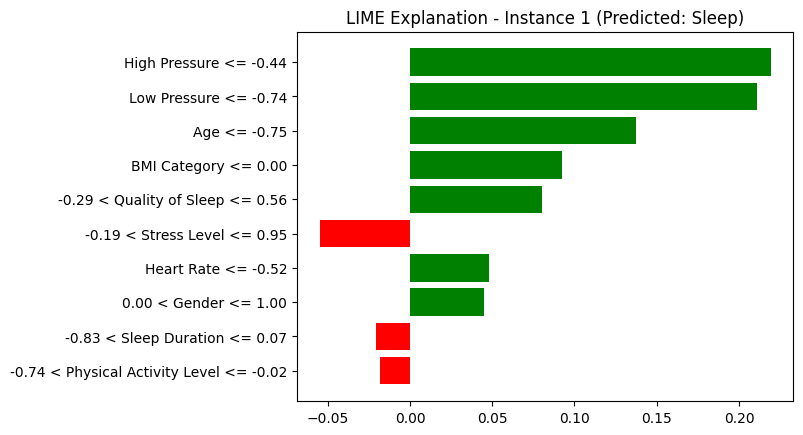


--- Instance #2 (test index 4) | Predicted: Sleep ---


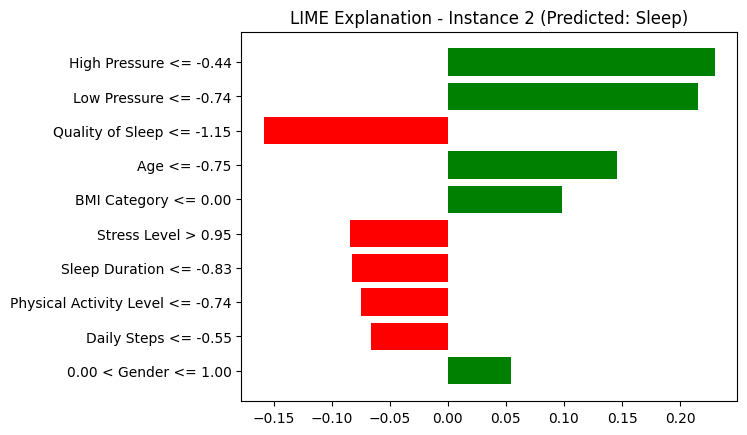


--- Instance #3 (test index 40) | Predicted: Not Sleep ---


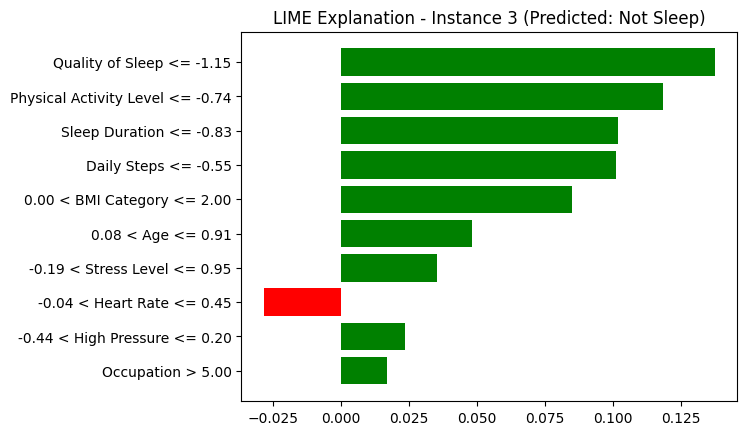

In [ ]:
import matplotlib.pyplot as plt

# === Mapping for class labels ===
class_names = ["Not Sleep", "Sleep"]  # 0 -> Not Sleep, 1 -> Sleep

# === Plot LIME explanations for a few random test instances ===
N_EXAMPLES = 3  # number of samples you want to visualize
np.random.seed(42)
idxs = np.random.choice(len(X_test_np), size=min(N_EXAMPLES, len(X_test_np)), replace=False)

for i, idx in enumerate(idxs, start=1):
    x0 = X_test_np[idx]
    exp = explainer.explain_instance(
        data_row=x0,
        predict_fn=best_global_model.predict_proba,
        num_features=min(10, X_test_np.shape[1]),
        top_labels=1
    )

    top_label = exp.top_labels[0]
    human_label = class_names[top_label]
    print(f"\n--- Instance #{i} (test index {idx}) | Predicted: {human_label} ---")

    # ==== Option 1: Inline Notebook Visualization (with readable labels) ====
    exp.show_in_notebook(show_table=True, show_all=False)

    # ==== Option 2: Matplotlib Figure (human-readable class name) ====
    fig = exp.as_pyplot_figure(label=top_label)
    plt.title(f"LIME Explanation - Instance {i} (Predicted: {human_label})")
    plt.show()



--- Instance #1 (test index 80) | Predicted: Sleep Apnea ---


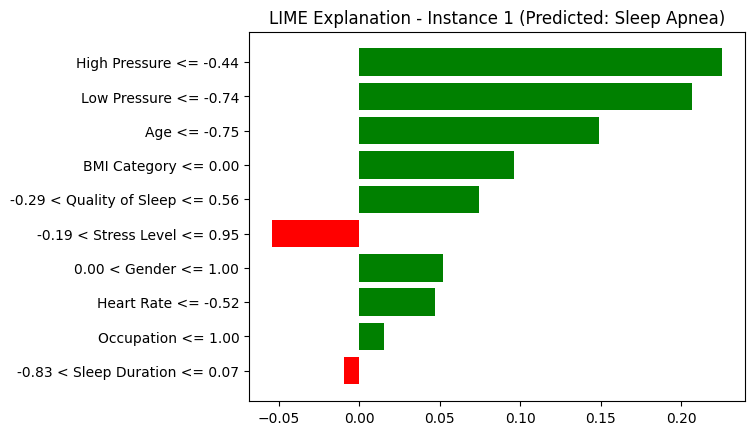

High Pressure <= -0.44                                        weight=+0.2257
Low Pressure <= -0.74                                         weight=+0.2071
Age <= -0.75                                                  weight=+0.1488
BMI Category <= 0.00                                          weight=+0.0962
-0.29 < Quality of Sleep <= 0.56                              weight=+0.0743
-0.19 < Stress Level <= 0.95                                  weight=-0.0546
0.00 < Gender <= 1.00                                         weight=+0.0519
Heart Rate <= -0.52                                           weight=+0.0468
Occupation <= 1.00                                            weight=+0.0151
-0.83 < Sleep Duration <= 0.07                                weight=-0.0097

--- Instance #2 (test index 4) | Predicted: Sleep Apnea ---


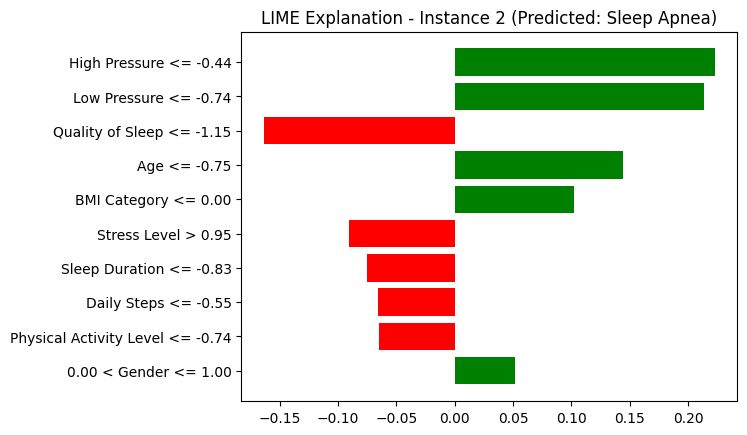

High Pressure <= -0.44                                        weight=+0.2229
Low Pressure <= -0.74                                         weight=+0.2134
Quality of Sleep <= -1.15                                     weight=-0.1636
Age <= -0.75                                                  weight=+0.1439
BMI Category <= 0.00                                          weight=+0.1020
Stress Level > 0.95                                           weight=-0.0909
Sleep Duration <= -0.83                                       weight=-0.0750
Daily Steps <= -0.55                                          weight=-0.0658
Physical Activity Level <= -0.74                              weight=-0.0646
0.00 < Gender <= 1.00                                         weight=+0.0521

--- Instance #3 (test index 40) | Predicted: Insomnia ---


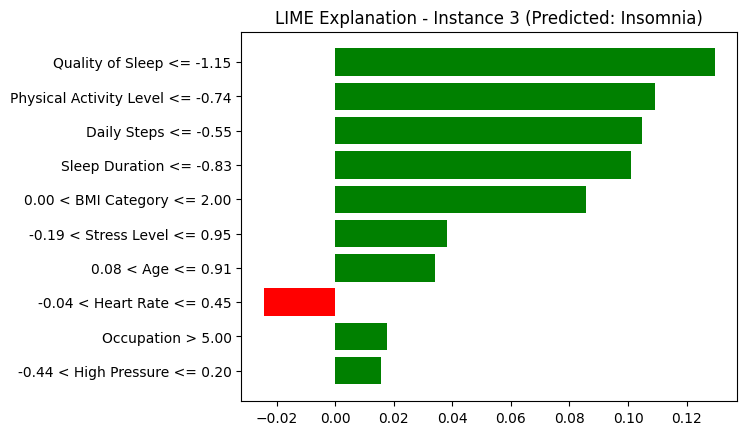

Quality of Sleep <= -1.15                                     weight=+0.1296
Physical Activity Level <= -0.74                              weight=+0.1091
Daily Steps <= -0.55                                          weight=+0.1046
Sleep Duration <= -0.83                                       weight=+0.1012
0.00 < BMI Category <= 2.00                                   weight=+0.0856
-0.19 < Stress Level <= 0.95                                  weight=+0.0383
0.08 < Age <= 0.91                                            weight=+0.0341
-0.04 < Heart Rate <= 0.45                                    weight=-0.0244
Occupation > 5.00                                             weight=+0.0175
-0.44 < High Pressure <= 0.20                                 weight=+0.0156


In [ ]:
# =========================================
# LIME plots: notebook-style (multiclass OK)
# =========================================
!pip -q install lime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lime.lime_tabular import LimeTabularExplainer

# ---------- 0) Choose which model to explain ----------
# If you want to explain your best_global_model from FL, keep this:
model_to_explain = best_global_model

# If you want to explain a single sklearn model (e.g., best MLP), use:
# model_to_explain = best_model   # (uncomment if you have it)

# ---------- 1) Make sure we have DataFrames with names ----------
def ensure_df(X, fallback_names=None):
    if hasattr(X, "columns"):
        return X.copy(), list(X.columns)
    X_df = pd.DataFrame(X)
    if fallback_names is not None and len(fallback_names) == X_df.shape[1]:
        X_df.columns = list(fallback_names)
        return X_df, list(fallback_names)
    X_df.columns = [f"f{i}" for i in range(X_df.shape[1])]
    return X_df, list(X_df.columns)

# If you already have num_col + cat_col lists, you can pass them to use as feature names:
try:
    fallback_feature_names = list(num_col) + list(cat_col)
except:
    fallback_feature_names = None

X_train_df, feature_names = ensure_df(X_train, fallback_feature_names)
X_test_df, _ = ensure_df(X_test, feature_names)

# ---------- 2) Class names (human-readable) ----------
# Option A: Auto from model classes (generic but safe)
auto_class_names = [str(c) for c in getattr(model_to_explain, "classes_", np.unique(y_train))]

# Option B (RECOMMENDED for your dataset): set explicit names (order must match model_to_explain.classes_)
# Example for sleep-disorder 3-class:
#   Suppose your y labels mapping is: 0->Insomnia, 1->Sleep Apnea, 2->None
#   Then set:
custom_class_names = ['Insomnia', 'Sleep Apnea', 'None']  # <-- EDIT if your order differs
use_custom_names = (len(custom_class_names) == len(auto_class_names))

class_names = custom_class_names if use_custom_names else auto_class_names

# ---------- 3) Build LIME explainer on TRAIN data (encoded/scaled is OK) ----------
explainer = LimeTabularExplainer(
    training_data=X_train_df.values,
    feature_names=feature_names,
    class_names=class_names,
    discretize_continuous=True,
    sample_around_instance=True,
    random_state=42,
    mode='classification'
)

# ---------- 4) Optional: pretty mapping for any encoded categorical FEATURE in plots ----------
# Example: if you have a feature column named 'Sleep Disorder' having 0/1 and you want
# to show "Not Sleep"/"Sleep" inside LIME text conditions, add a mapping here.
# You can add multiple feature mappings.
feature_value_maps = {
    # 'Sleep Disorder': {0: 'Not Sleep', 1: 'Sleep'}
}

def pretty_condition_text(cond_text):
    # Replace "Feature=value" with mapped text if available
    # Works for patterns like "Sleep Disorder <= 0.50" or "Sleep Disorder = 1"
    for feat, mp in feature_value_maps.items():
        for k, v in mp.items():
            cond_text = cond_text.replace(f"{feat} = {k}", f"{feat} = {v}")
            cond_text = cond_text.replace(f"{feat}={k}",  f"{feat}={v}")
    return cond_text

# ---------- 5) Explain a few random test instances & plot ----------
N_EXAMPLES = 3
np.random.seed(42)
idxs = np.random.choice(len(X_test_df), size=min(N_EXAMPLES, len(X_test_df)), replace=False)

for i, idx in enumerate(idxs, start=1):
    x0 = X_test_df.iloc[idx].values
    exp = explainer.explain_instance(
        data_row=x0,
        predict_fn=model_to_explain.predict_proba,
        num_features=min(10, X_test_df.shape[1]),
        top_labels=1
    )
    top_label = exp.top_labels[0]
    print(f"\n--- Instance #{i} (test index {idx}) | Predicted: {class_names[top_label]} ---")

    # (A) Notebook table view (same style as your sample)
    exp.show_in_notebook(show_table=True, show_all=False)

    # (B) Matplotlib figure (bar plot) — same vibe as sample
    fig = exp.as_pyplot_figure(label=top_label)
    plt.title(f"LIME Explanation - Instance {i} (Predicted: {class_names[top_label]})")
    plt.show()

    # (C) If you also want the raw list with pretty feature text (optional)
    pairs = exp.as_list(label=top_label)  # [(condition_text, weight)]
    pairs_pretty = [(pretty_condition_text(ft), w) for ft, w in pairs]
    # Print a compact pretty list:
    for ft, w in pairs_pretty:
        print(f"{ft:60s}  weight={w:+.4f}")


XAI-SHAP

PermutationExplainer explainer: 114it [00:36,  2.21it/s]
/tmp/ipython-input-2031110547.py:44: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_test, feature_names=feature_names, show=True)


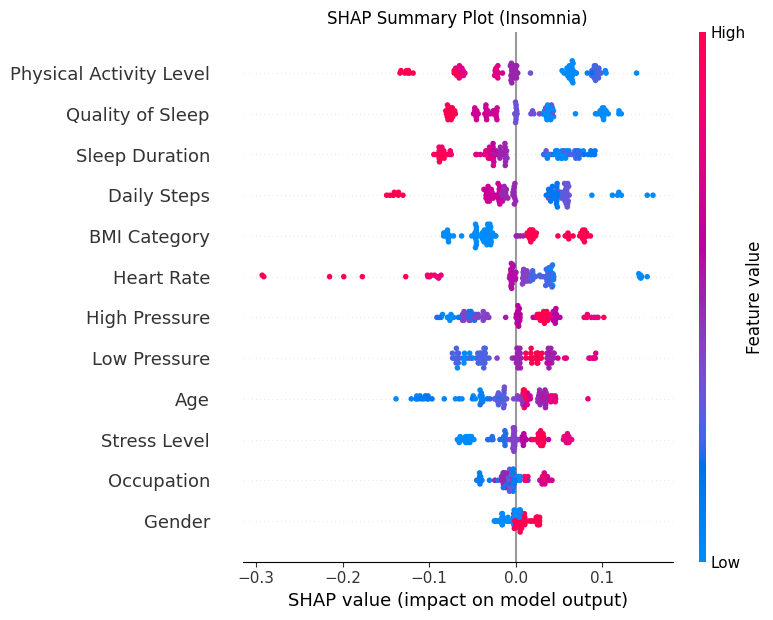

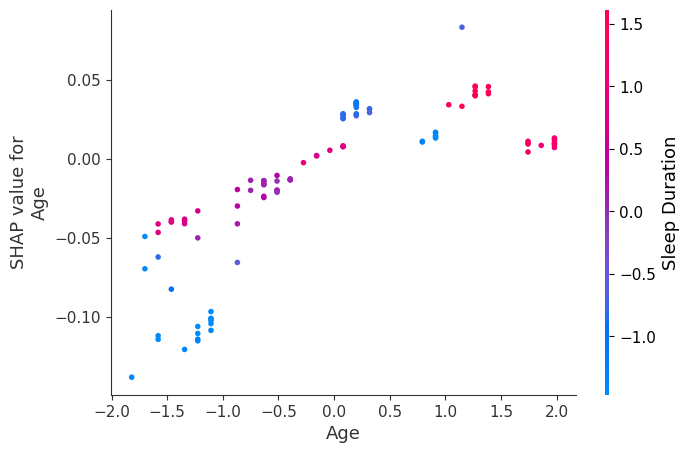

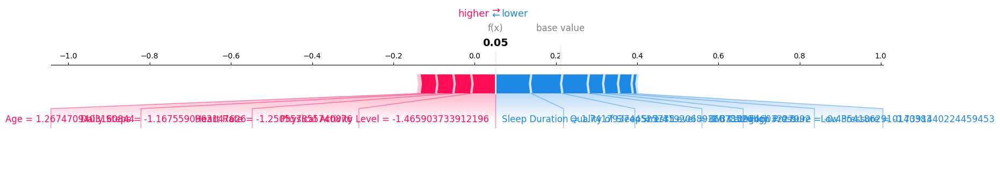

In [ ]:
# ============================
# SHAP visualizations (summary, dependence, force plot) — fixed
# ============================
!pip -q install shap
import shap
import numpy as np
import matplotlib.pyplot as plt

# ---- 0) Choose model to explain ----
model_to_explain = best_global_model   # or best_model

# ---- 1) Build PermutationExplainer (model-agnostic) ----
# If X_train is a NumPy array, feature_names=None is fine
feature_names = getattr(X_train, "columns", None)
explainer = shap.PermutationExplainer(
    model_to_explain.predict_proba,
    X_train,                      # background / masker
    feature_names=feature_names
)

# ---- 2) Compute SHAP values on test data ----
shap_values = explainer(X_test)   # returns a shap.Explanation

# Choose which class to visualize (index into model_to_explain.classes_)
# For multiclass, set by name if you have class_names; else use index 0
try:
    class_names  # from your LIME block
except NameError:
    # fallback: string versions of model classes (works for binary/multiclass)
    class_names = [str(c) for c in getattr(model_to_explain, "classes_", [0,1])]

target_class_name = class_names[0]           # e.g. 'Insomnia' or 'Sleep'
try:
    class_index = list(class_names).index(target_class_name)
except ValueError:
    class_index = 0

# Convenience variables
sv = shap_values.values[:, :, class_index]   # [n_samples, n_features]
bv = shap_values.base_values[:, class_index] # [n_samples]

# ---- 3) Summary plot (beeswarm) for chosen class ----
plt.title(f"SHAP Summary Plot ({target_class_name})")
shap.summary_plot(sv, X_test, feature_names=feature_names, show=True)

# ---- 4) Dependence plot for a specific feature ----
# Replace "Age" with a real column; if you use NumPy data, pass feature index instead.
if feature_names is not None and "Age" in feature_names:
    shap.dependence_plot("Age", sv, X_test, feature_names=feature_names, show=True)
# else:
#     shap.dependence_plot(0, sv, X_test, feature_names=feature_names, show=True)  # feature index 0 as example

# ---- 5) Force plot for a specific instance ----
instance_index = 0
shap.initjs()  # for interactive JS version (works in notebooks)

# Interactive (JS) force plot:
shap.force_plot(
    bv[instance_index],                 # base value for this instance & class
    sv[instance_index, :],              # shap values for this instance & class
    (X_test.iloc[instance_index] if hasattr(X_test, "iloc") else X_test[instance_index]),
    feature_names=feature_names
)

# Static (matplotlib) force plot for saving/printing:
shap.force_plot(
    bv[instance_index],
    sv[instance_index, :],
    (X_test.iloc[instance_index] if hasattr(X_test, "iloc") else X_test[instance_index]),
    feature_names=feature_names,
    matplotlib=True
)
plt.show()
